# Phase 5 - Baseline Secuencial

Notebook baseline para secuencias de silabas/token:
- n-gramas
- matriz de transicion
- HMM discreto (regimenes ocultos)

Usa como entrada el `token_stream_full` generado en el notebook 1 de phase5.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hmmlearn.hmm import CategoricalHMM

pd.set_option('display.max_columns', 220)
pd.set_option('display.width', 260)


In [2]:
# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
MODEL_TAG = 'v2'
NGRAM_LIST = [2, 3, 4]
HMM_STATES_CANDIDATES = [2, 3, 4, 5, 6, 7, 8]
HMM_MAX_ITER = 400
HMM_RANDOM_STATE = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
MIN_SEQ_LEN_FOR_HMM = 200

IN_DIR = Path('./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2')
STREAM_FULL_PATH = IN_DIR / 'GBPUSD_token_stream_full.parquet'
STREAM_INF_PATH = IN_DIR / 'GBPUSD_token_stream_informative.parquet'
VOCAB_PATH = IN_DIR / 'GBPUSD_token_vocabulary.json'

OUT_DIR = Path('./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2')
OUT_DIR.mkdir(parents=True, exist_ok=True)

NGRAM_FULL_PREFIX = OUT_DIR / 'GBPUSD_ngrams_full'
NGRAM_INF_PREFIX = OUT_DIR / 'GBPUSD_ngrams_informative'
TRANS_CNT_CSV = OUT_DIR / 'GBPUSD_transition_counts_full.csv'
TRANS_PROB_CSV = OUT_DIR / 'GBPUSD_transition_probs_full.csv'
HMM_MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_hmm_model_selection.csv'
HMM_STATE_STREAM_PQ = OUT_DIR / 'GBPUSD_token_stream_with_hmm_state.parquet'
HMM_STATE_STREAM_CSV = OUT_DIR / 'GBPUSD_token_stream_with_hmm_state.csv'
HMM_TRANS_CSV = OUT_DIR / 'GBPUSD_hmm_transmat.csv'
HMM_EMISS_CSV = OUT_DIR / 'GBPUSD_hmm_emission_probs.csv'
HMM_STATE_PROFILE_CSV = OUT_DIR / 'GBPUSD_hmm_state_profile.csv'
HMM_MODEL_JOBLIB = OUT_DIR / 'GBPUSD_hmm_model.joblib'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_baseline_summary.json'

print('STREAM_FULL_PATH =', STREAM_FULL_PATH)
print('OUT_DIR =', OUT_DIR)


STREAM_FULL_PATH = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_token_stream_full.parquet
OUT_DIR = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2


In [3]:
# =========================
# Helpers
# =========================
def check_inputs(paths):
    for p in paths:
        if not p.exists():
            raise FileNotFoundError(f'Missing input: {p}')


def load_stream(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path).copy()
    if 'start_ts' in df.columns:
        df['start_ts'] = pd.to_datetime(df['start_ts'], errors='coerce')
    if 'end_ts' in df.columns:
        df['end_ts'] = pd.to_datetime(df['end_ts'], errors='coerce')
    df = df.sort_values(['start_ts', 'event_idx']).reset_index(drop=True)
    return df


def make_ngrams(tokens, n: int) -> pd.DataFrame:
    vals = list(map(str, tokens))
    if len(vals) < n:
        return pd.DataFrame(columns=['ngram', 'count', 'pct'])

    out = {}
    for i in range(0, len(vals) - n + 1):
        g = tuple(vals[i:i+n])
        out[g] = out.get(g, 0) + 1

    df = pd.DataFrame({
        'ngram': ['|'.join(k) for k in out.keys()],
        'count': list(out.values()),
    })
    df['pct'] = df['count'] / df['count'].sum()
    df = df.sort_values('count', ascending=False).reset_index(drop=True)
    return df


def transition_tables(tokens: pd.Series):
    s0 = tokens.astype(str)
    s1 = s0.shift(-1)
    tmp = pd.DataFrame({'src': s0, 'dst': s1}).dropna()
    if tmp.empty:
        return pd.DataFrame(), pd.DataFrame()
    cnt = pd.crosstab(tmp['src'], tmp['dst'])
    prob = cnt.div(cnt.sum(axis=1), axis=0).fillna(0.0)
    return cnt, prob


def temporal_split_indices(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test


def hmm_num_params(n_states: int, vocab_size: int) -> int:
    # startprob (K-1) + transmat K*(K-1) + emission K*(V-1)
    return (n_states - 1) + n_states * (n_states - 1) + n_states * (vocab_size - 1)


def fit_hmm(obs_train: np.ndarray, n_states: int, random_state: int = 42, max_iter: int = 300):
    model = CategoricalHMM(
        n_components=n_states,
        random_state=random_state,
        n_iter=max_iter,
        tol=1e-4,
        verbose=False,
    )
    model.fit(obs_train.reshape(-1, 1), lengths=[len(obs_train)])
    return model


In [4]:
# =========================
# Load data
# =========================
check_inputs([STREAM_FULL_PATH, STREAM_INF_PATH, VOCAB_PATH])

DF_FULL = load_stream(STREAM_FULL_PATH)
DF_INF = load_stream(STREAM_INF_PATH)
VOCAB = json.loads(VOCAB_PATH.read_text())
token_to_id = VOCAB['token_to_id']

DF_FULL['token_id'] = DF_FULL['token'].map(token_to_id).astype(int)
DF_INF['token_id'] = DF_INF['token'].map(token_to_id).astype(int)

print('DF_FULL rows =', len(DF_FULL))
print('DF_INF rows =', len(DF_INF))
print('vocab size =', len(token_to_id))
print('time range full =', DF_FULL['start_ts'].min(), '->', DF_FULL['start_ts'].max())
display(DF_FULL.head(3))


DF_FULL rows = 1636
DF_INF rows = 434
vocab size = 9
time range full = 2000-05-31 10:00:00 -> 2025-10-29 07:00:00


,global_segment_id,symbol,start_ts,end_ts,n_bars,move_pips,range_pips,score_event,length,cluster_id,cluster_dist,is_informative_cluster,cluster_dist_norm,score_event_norm,selection_score,token,event_idx,duration_h,delta_prev_h,move_sign,prev_token_1,prev_cluster_1,prev_token_2,prev_cluster_2,prev_token_3,prev_cluster_3,prev_token_4,prev_cluster_4,prev_token_5,prev_cluster_5,token_id
0,GBPUSD_seg_00000,GBPUSD,2000-05-31 10:00:00,2000-06-01 02:00:00,17,41.999817,325.000286,8.000000,17,3,3.055548,False,0.859840,1.000000,0.264016,c03,0,16.0,0.0,1,BOS,-1,BOS,-1,BOS,-1,BOS,-1,BOS,-1,3
1,GBPUSD_seg_00001,GBPUSD,2000-06-02 02:00:00,2000-06-04 20:00:00,17,144.000053,189.999342,8.000000,17,1,0.443041,False,0.104134,1.000000,0.339587,c01,1,66.0,40.0,1,c03,3,BOS,-1,BOS,-1,BOS,-1,BOS,-1,1
2,GBPUSD_seg_00002,GBPUSD,2000-06-08 02:00:00,2000-06-08 20:00:00,17,-85.000992,162.000656,7.643173,17,8,0.637773,False,0.160463,0.846379,0.295549,c08,2,18.0,144.0,-1,c01,1,c03,3,BOS,-1,BOS,-1,BOS,-1,7


In [5]:
# =========================
# n-grams baseline
# =========================
for n in NGRAM_LIST:
    ng_full = make_ngrams(DF_FULL['token'], n=n)
    ng_inf = make_ngrams(DF_INF['token'], n=n)

    ng_full.to_csv(str(NGRAM_FULL_PREFIX) + f'_n{n}.csv', index=False)
    ng_inf.to_csv(str(NGRAM_INF_PREFIX) + f'_n{n}.csv', index=False)

    print(f'n={n} | full unique ngrams={len(ng_full)} | inf unique ngrams={len(ng_inf)}')
    display(ng_full.head(10))


n=2 | full unique ngrams=68 | inf unique ngrams=4


,ngram,count,pct
0,c01|c01,64,0.039144
1,c07|c01,47,0.028746
2,c02|c01,47,0.028746
3,c01|c02,46,0.028135
4,c02|c07,44,0.026911
5,c04|c04,43,0.026300
6,c01|c04,43,0.026300
7,c01|c07,42,0.025688
8,c04|c02,41,0.025076
9,c02|c08,40,0.024465


n=3 | full unique ngrams=452 | inf unique ngrams=8


,ngram,count,pct
0,c01|c01|c01,20,0.012240
1,c01|c02|c01,13,0.007956
2,c01|c02|c07,11,0.006732
3,c01|c04|c02,11,0.006732
4,c07|c01|c01,11,0.006732
5,c02|c04|c04,11,0.006732
6,c02|c07|c09,10,0.006120
7,c09|c01|c01,10,0.006120
8,c02|c08|c04,10,0.006120
9,c01|c01|c02,10,0.006120


n=4 | full unique ngrams=1234 | inf unique ngrams=16


,ngram,count,pct
0,c01|c01|c01|c01,7,0.004287
1,c02|c04|c04|c09,6,0.003674
2,c01|c01|c01|c04,5,0.003062
3,c01|c01|c02|c07,5,0.003062
4,c08|c02|c07|c09,5,0.003062
5,c02|c01|c01|c07,4,0.002449
6,c01|c07|c01|c04,4,0.002449
7,c07|c01|c01|c01,4,0.002449
8,c02|c08|c04|c08,4,0.002449
9,c07|c08|c07|c04,4,0.002449


In [6]:
# =========================
# Transition matrix baseline
# =========================
T_CNT, T_PROB = transition_tables(DF_FULL['token'])
T_CNT.to_csv(TRANS_CNT_CSV)
T_PROB.to_csv(TRANS_PROB_CSV)

print('T_CNT shape =', T_CNT.shape, '| saved =', TRANS_CNT_CSV)
print('T_PROB shape =', T_PROB.shape, '| saved =', TRANS_PROB_CSV)
display(T_PROB.head(10))


T_CNT shape = (9, 9) | saved = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_transition_counts_full.csv
T_PROB shape = (9, 9) | saved = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_transition_probs_full.csv


dst,c00,c01,c02,c03,c04,c05,c07,c08,c09
src,,,,,,,,,
c00,0.026316,0.236842,0.184211,0.144737,0.092105,0.000000,0.131579,0.105263,0.078947
c01,0.055921,0.210526,0.151316,0.072368,0.141447,0.000000,0.138158,0.118421,0.111842
c02,0.049180,0.192623,0.110656,0.049180,0.163934,0.004098,0.180328,0.163934,0.086066
c03,0.054264,0.232558,0.178295,0.124031,0.093023,0.000000,0.131783,0.077519,0.108527
c04,0.036290,0.149194,0.165323,0.068548,0.173387,0.000000,0.137097,0.125000,0.145161
c05,0.000000,0.000000,0.500000,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
c07,0.053942,0.195021,0.157676,0.078838,0.149378,0.004149,0.120332,0.107884,0.132780
c08,0.043902,0.126829,0.141463,0.068293,0.185366,0.000000,0.165854,0.156098,0.112195
c09,0.037634,0.188172,0.134409,0.091398,0.150538,0.000000,0.172043,0.118280,0.107527


In [7]:
# =========================
# HMM model selection (temporal train/val/test)
# =========================
obs_all = DF_FULL['token_id'].to_numpy(dtype=int)
n_obs = len(obs_all)
if n_obs < MIN_SEQ_LEN_FOR_HMM:
    raise RuntimeError(f'Not enough observations for HMM: {n_obs}')

idx_train, idx_val, idx_test = temporal_split_indices(n_obs, TRAIN_RATIO, VAL_RATIO)
obs_train = obs_all[idx_train]
obs_val = obs_all[idx_val]
obs_test = obs_all[idx_test]

rows = []
for k in HMM_STATES_CANDIDATES:
    try:
        m = fit_hmm(obs_train, n_states=k, random_state=HMM_RANDOM_STATE, max_iter=HMM_MAX_ITER)
        ll_train = float(m.score(obs_train.reshape(-1, 1), lengths=[len(obs_train)]))
        ll_val = float(m.score(obs_val.reshape(-1, 1), lengths=[len(obs_val)]))
        ll_test = float(m.score(obs_test.reshape(-1, 1), lengths=[len(obs_test)]))

        p = hmm_num_params(k, len(token_to_id))
        bic_val = -2.0 * ll_val + p * np.log(max(2, len(obs_val)))
        aic_val = -2.0 * ll_val + 2.0 * p

        rows.append({
            'n_states': int(k),
            'll_train': ll_train,
            'll_val': ll_val,
            'll_test': ll_test,
            'll_val_per_step': ll_val / max(1, len(obs_val)),
            'll_test_per_step': ll_test / max(1, len(obs_test)),
            'bic_val': float(bic_val),
            'aic_val': float(aic_val),
        })
    except Exception as e:
        rows.append({
            'n_states': int(k),
            'll_train': np.nan,
            'll_val': np.nan,
            'll_test': np.nan,
            'll_val_per_step': np.nan,
            'll_test_per_step': np.nan,
            'bic_val': np.nan,
            'aic_val': np.nan,
            'error': str(e),
        })

DF_SEL = pd.DataFrame(rows).sort_values('bic_val', ascending=True, na_position='last').reset_index(drop=True)
DF_SEL.to_csv(HMM_MODEL_SELECTION_CSV, index=False)

best_row = DF_SEL.iloc[0]
BEST_K = int(best_row['n_states'])

print('split sizes: train/val/test =', len(obs_train), len(obs_val), len(obs_test))
print('BEST_K by BIC(val) =', BEST_K)
display(DF_SEL)


split sizes: train/val/test = 1145 245 246
BEST_K by BIC(val) = 2


,n_states,ll_train,ll_val,ll_test,ll_val_per_step,ll_test_per_step,bic_val,aic_val
0,2,-2305.525502,-494.491027,-513.344409,-2.018331,-2.086766,1093.505959,1026.982053
1,3,-2266.600208,-496.903994,-519.629215,-2.028180,-2.112314,1169.848251,1057.807989
2,4,-2264.121291,-501.123892,-515.802388,-2.045404,-2.096758,1260.806920,1096.247784
3,5,-2253.454445,-503.040449,-520.280143,-2.053226,-2.114960,1358.161423,1134.080898
4,6,-2240.760021,-502.017857,-527.059361,-2.049052,-2.142518,1460.640146,1170.035714
5,7,-2233.976228,-640.400370,-690.226486,-2.613879,-2.805799,1852.931593,1488.800739
6,8,-2227.448398,-665.701870,-679.522341,-2.717150,-2.762286,2030.063532,1585.403740


In [8]:
# =========================
# Fit final HMM (train+val), decode all stream
# =========================
obs_trainval = np.concatenate([obs_train, obs_val])
HMM_FINAL = fit_hmm(obs_trainval, n_states=BEST_K, random_state=HMM_RANDOM_STATE, max_iter=HMM_MAX_ITER)

# test score (out-of-sample)
ll_test_final = float(HMM_FINAL.score(obs_test.reshape(-1, 1), lengths=[len(obs_test)]))
ll_test_per_step = ll_test_final / max(1, len(obs_test))

states_all = HMM_FINAL.predict(obs_all.reshape(-1, 1), lengths=[len(obs_all)])
DF_STATE = DF_FULL.copy()
DF_STATE['hmm_state'] = states_all.astype(int)

DF_STATE.to_parquet(HMM_STATE_STREAM_PQ, index=False)
DF_STATE.to_csv(HMM_STATE_STREAM_CSV, index=False)

trans = pd.DataFrame(HMM_FINAL.transmat_, index=[f's{i}' for i in range(BEST_K)], columns=[f's{i}' for i in range(BEST_K)])
emiss = pd.DataFrame(HMM_FINAL.emissionprob_, index=[f's{i}' for i in range(BEST_K)], columns=[f'tok_{i}' for i in range(HMM_FINAL.emissionprob_.shape[1])])

# rename emissions to token labels where possible
id_to_token = {int(v): k for k, v in token_to_id.items()}
emiss = emiss.rename(columns={f'tok_{i}': id_to_token.get(i, f'tok_{i}') for i in range(emiss.shape[1])})

trans.to_csv(HMM_TRANS_CSV)
emiss.to_csv(HMM_EMISS_CSV)
joblib.dump(HMM_FINAL, HMM_MODEL_JOBLIB)

# state profile
prof = DF_STATE.groupby('hmm_state').agg(
    n=('hmm_state', 'size'),
    mean_move_pips=('move_pips', 'mean'),
    mean_range_pips=('range_pips', 'mean'),
    mean_delta_prev_h=('delta_prev_h', 'mean'),
).reset_index()

top_tok = (DF_STATE.groupby(['hmm_state', 'token']).size().rename('cnt').reset_index()
           .sort_values(['hmm_state', 'cnt'], ascending=[True, False]))
top_tok['rank'] = top_tok.groupby('hmm_state')['cnt'].rank(method='first', ascending=False)
top_tok = top_tok[top_tok['rank'] <= 3]
top_tok['token_rank'] = top_tok['token'] + ':' + top_tok['cnt'].astype(int).astype(str)
top_tok = top_tok.groupby('hmm_state')['token_rank'].apply(lambda x: ', '.join(x)).reset_index(name='top_tokens')

prof = prof.merge(top_tok, on='hmm_state', how='left').sort_values('n', ascending=False).reset_index(drop=True)
prof.to_csv(HMM_STATE_PROFILE_CSV, index=False)

summary = {
    'symbol': SYMBOL,
    'model_tag': MODEL_TAG,
    'n_obs': int(n_obs),
    'train_size': int(len(obs_train)),
    'val_size': int(len(obs_val)),
    'test_size': int(len(obs_test)),
    'best_k': int(BEST_K),
    'll_test_final': float(ll_test_final),
    'll_test_per_step': float(ll_test_per_step),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved stream w/ states =', HMM_STATE_STREAM_PQ)
print('saved transmat =', HMM_TRANS_CSV)
print('saved emission =', HMM_EMISS_CSV)
print('saved state profile =', HMM_STATE_PROFILE_CSV)
print('BEST_K =', BEST_K, '| test ll/step =', round(ll_test_per_step, 6))
display(prof)


saved stream w/ states = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_token_stream_with_hmm_state.parquet
saved transmat = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_hmm_transmat.csv
saved emission = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_hmm_emission_probs.csv
saved state profile = ./phases/phase05_context_sequencing/output_baseline_secuencial_GBPUSD_v2/GBPUSD_hmm_state_profile.csv
BEST_K = 2 | test ll/step = -2.081572


,hmm_state,n,mean_move_pips,mean_range_pips,mean_delta_prev_h,top_tokens
0,0,952,-13.201470,201.550429,143.622899,"c02:244, c09:186, c01:176"
1,1,684,10.339782,180.929186,125.783626,"c07:199, c08:146, c01:128"


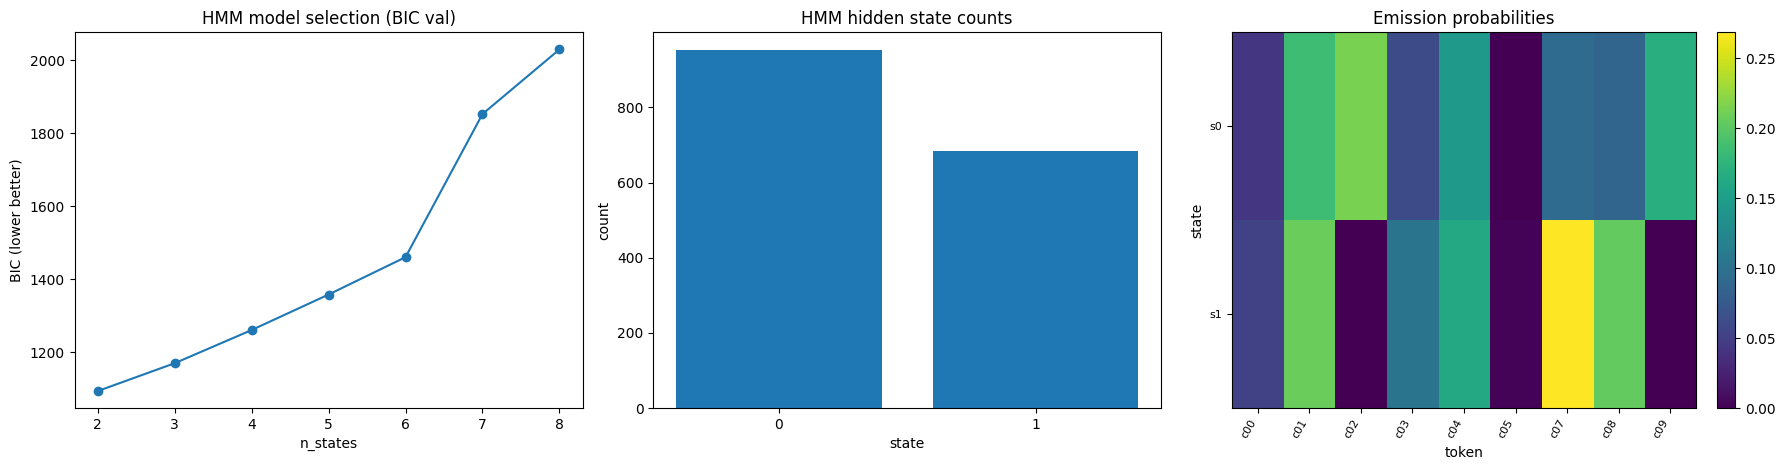

In [9]:
# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1) model selection by BIC
d = DF_SEL.dropna(subset=['bic_val']).copy()
axes[0].plot(d['n_states'], d['bic_val'], marker='o')
axes[0].set_title('HMM model selection (BIC val)')
axes[0].set_xlabel('n_states')
axes[0].set_ylabel('BIC (lower better)')

# 2) state counts
cnt = DF_STATE['hmm_state'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('HMM hidden state counts')
axes[1].set_xlabel('state')
axes[1].set_ylabel('count')

# 3) emission heatmap-like
im = axes[2].imshow(emiss.to_numpy(dtype=float), aspect='auto')
axes[2].set_title('Emission probabilities')
axes[2].set_xlabel('token')
axes[2].set_ylabel('state')
axes[2].set_xticks(np.arange(emiss.shape[1]))
axes[2].set_xticklabels(list(emiss.columns), rotation=60, ha='right', fontsize=8)
axes[2].set_yticks(np.arange(emiss.shape[0]))
axes[2].set_yticklabels(list(emiss.index), fontsize=8)
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()


## Artefactos que deja este notebook

- `GBPUSD_ngrams_*_n{2,3,4}.csv`
- `GBPUSD_transition_counts_full.csv`
- `GBPUSD_transition_probs_full.csv`
- `GBPUSD_hmm_model_selection.csv`
- `GBPUSD_token_stream_with_hmm_state.parquet`
- `GBPUSD_hmm_transmat.csv` y `GBPUSD_hmm_emission_probs.csv`
- `GBPUSD_hmm_state_profile.csv`
- `GBPUSD_hmm_model.joblib`